## 01 — Setup and Shared Storage

In [31]:
from pathlib import Path
import os, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
SEED = 42
# Optional shared storage: mount Drive for persistent files across Colab notebooks.
if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    ROOT = Path('/content/drive/MyDrive/CAI470_Project')
else:
    ROOT = Path.cwd() / 'CAI470_Project'
RAW = ROOT / 'raw'
OUT = ROOT / 'outputs'
FIG = OUT / 'figures'
for p in [RAW, OUT, FIG]: p.mkdir(parents=True, exist_ok=True)
print('Shared project folder:', ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Shared project folder: /content/drive/MyDrive/CAI470_Project


## 02 — Load Model Results

In [32]:
comparison_path=OUT/'model_comparison.csv'; predictions_path=OUT/'test_predictions.csv'
assert comparison_path.exists() and predictions_path.exists(), 'Run Notebook 02 through Save Reusable Results using the same Google Drive folder.'
results=pd.read_csv(comparison_path)
preds=pd.read_csv(predictions_path)
assert len(results)==4 and len(preds)==82332
assert {'actual','attack_cat','id'}.issubset(preds.columns)
display(results.round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,FP,FN,TP,TN,Fit seconds
0,HistGradientBoosting,0.8729,0.8210,0.9835,0.8950,0.9855,0.9895,9719,747,44585,27281,12.99
1,Random Forest,0.8652,0.8086,0.9893,0.8899,0.9823,0.9868,10616,483,44849,26384,114.73
2,Decision Tree,0.8680,0.8269,0.9615,0.8891,0.9106,0.8806,9125,1746,43586,27875,13.04
3,Logistic Regression,0.8355,0.8022,0.9306,0.8617,0.9560,0.9666,10400,3145,42187,26600,15.63


Load Validation-Selected Model

In [33]:

import json

selection_path = OUT / "best_model.json"

assert selection_path.exists(), (
    "Run updated Notebook 02 first."
)

selection = json.loads(
    selection_path.read_text(encoding="utf-8")
)

assert selection["selection_metric"] == "Validation F1"

best_name = selection["best_model"]

assert best_name in results["Model"].values

print("Selected using Validation:", best_name)

display(
    results.loc[
        results["Model"] == best_name
    ]
)


Selected using Validation: Random Forest


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,FP,FN,TP,TN,Fit seconds
1,Random Forest,0.865192,0.8086,0.989345,0.889888,0.982327,0.986787,10616,483,44849,26384,114.73


## 03 — Recheck Class Distribution

In [34]:
print(preds['actual'].value_counts().rename({0:'Normal',1:'Attack'}))
print('Positive class: Attack = 1')

actual
Attack    45332
Normal    37000
Name: count, dtype: int64
Positive class: Attack = 1


## 04 — Compare Four Algorithms

,Model,Accuracy,Precision,Recall,F1-score,FP,FN
0,HistGradientBoosting,0.8729,0.8210,0.9835,0.8950,9719,747
1,Random Forest,0.8652,0.8086,0.9893,0.8899,10616,483
2,Decision Tree,0.8680,0.8269,0.9615,0.8891,9125,1746
3,Logistic Regression,0.8355,0.8022,0.9306,0.8617,10400,3145


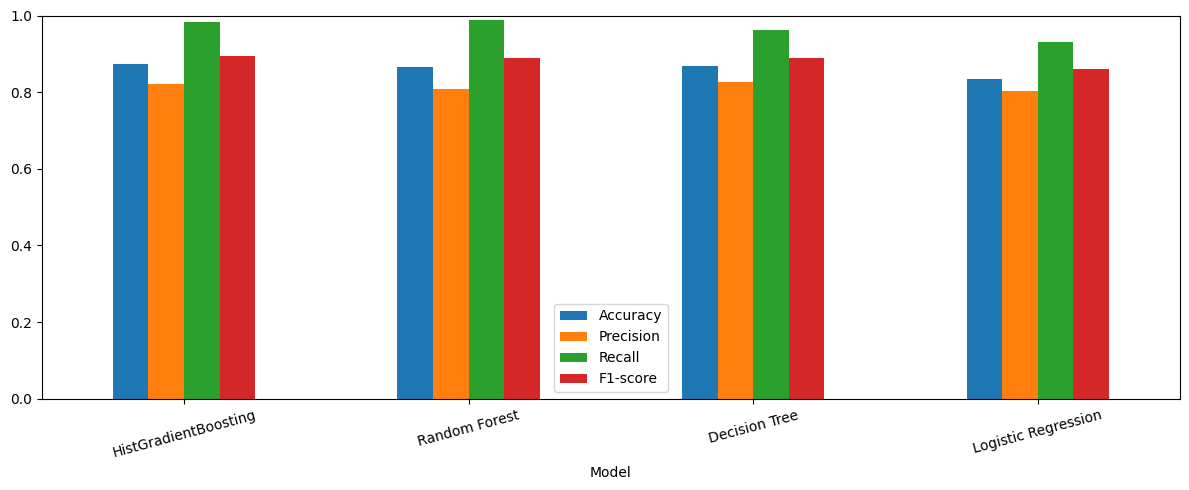

In [35]:
cols=['Model','Accuracy','Precision','Recall','F1-score','FP','FN']
display(results[cols].sort_values('F1-score',ascending=False).round(4))
results.set_index('Model')[['Accuracy','Precision','Recall','F1-score']].plot.bar(figsize=(12,5),ylim=(0,1),rot=15)
plt.tight_layout();plt.savefig(FIG/'final_model_comparison.png',dpi=150);plt.show()

## 05 — Confusion Matrices

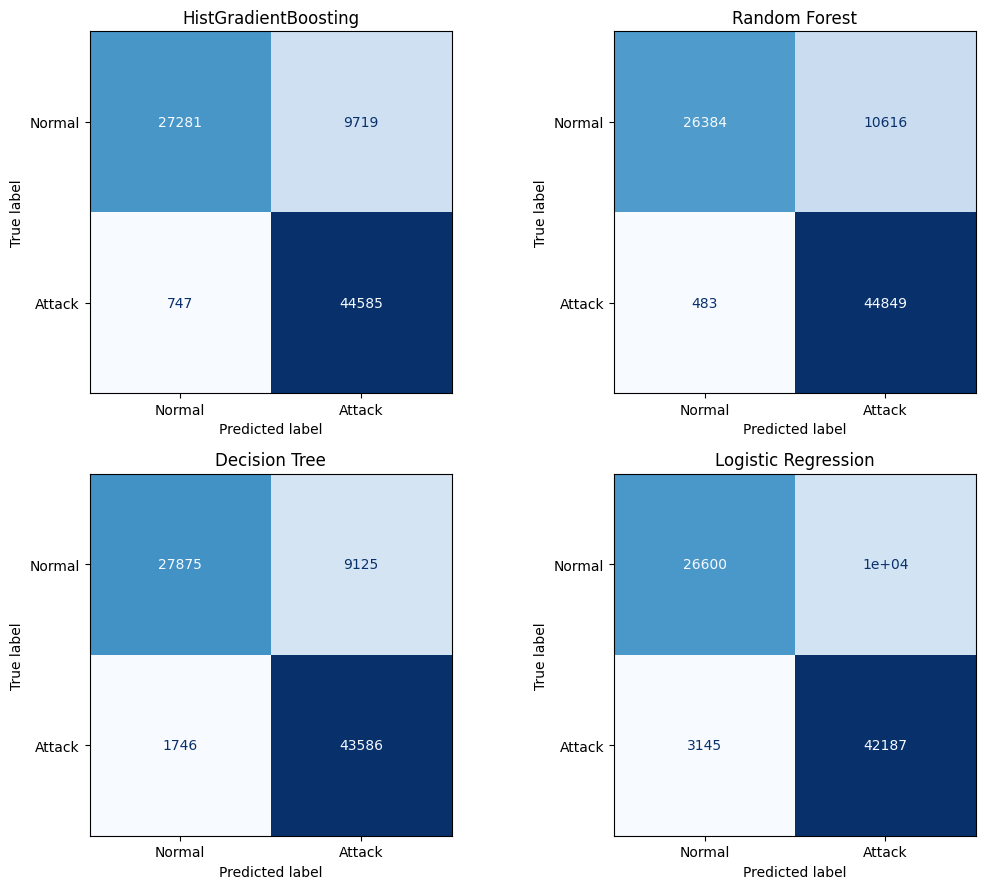

In [36]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
fig,axes=plt.subplots(2,2,figsize=(11,9))
for ax,name in zip(axes.flat,results.Model):
    tag=name.lower().replace(' ','_'); col=tag+'_prediction'
    assert col in preds
    cm=confusion_matrix(preds.actual,preds[col],labels=[0,1])
    ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=['Normal','Attack']).plot(ax=ax,cmap='Blues',colorbar=False)
    ax.set_title(name)
plt.tight_layout();plt.savefig(FIG/'final_confusion_matrices.png',dpi=150);plt.show()

## 06 — False Positives and False Negatives

In [37]:
error_rows=[]
for name in results.Model:
    tag=name.lower().replace(' ','_')
    p=preds[tag+'_prediction'].astype(int);y=preds.actual.astype(int)
    error_rows.append({'Model':name,'False Positives':int(((y==0)&(p==1)).sum()),'False Negatives':int(((y==1)&(p==0)).sum()),'Attack Recall':float((p[y==1]==1).mean())})
error_df=pd.DataFrame(error_rows).sort_values('False Negatives')
display(error_df)
error_df.to_csv(OUT/'security_errors.csv',index=False)

,Model,False Positives,False Negatives,Attack Recall
1,Random Forest,10616,483,0.989345
0,HistGradientBoosting,9719,747,0.983522
2,Decision Tree,9125,1746,0.961484
3,Logistic Regression,10400,3145,0.930623


Duplicate Impact on Final Test

In [38]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

overlap_path = OUT / "test_overlap_audit.csv"

assert overlap_path.exists(), (
    "Run Notebook 01 duplicate audit first."
)

overlap = pd.read_csv(overlap_path)

assert len(overlap) == len(preds)
assert np.array_equal(
    overlap["actual_label"].to_numpy(),
    preds["actual"].to_numpy()
), "Test row order or labels do not match."

pred_col = (
    best_name.lower().replace(" ", "_")
    + "_prediction"
)

assert pred_col in preds.columns

y_true = preds["actual"].astype(int).to_numpy()
y_pred = preds[pred_col].astype(int).to_numpy()

shared_mask = (
    overlap["overlaps_training"]
    .astype(bool)
    .to_numpy()
)

groups = {
    "Full Test": np.ones(len(preds), dtype=bool),
    "Overlapping Test Records": shared_mask,
    "Non-overlapping Test Records": ~shared_mask
}

comparison = []

for group_name, mask in groups.items():

    if mask.sum() == 0:
        continue

    actual = y_true[mask]
    predicted = y_pred[mask]

    fn = int(
        ((actual == 1) & (predicted == 0)).sum()
    )

    fp = int(
        ((actual == 0) & (predicted == 1)).sum()
    )

    comparison.append({
        "Group": group_name,
        "Records": int(mask.sum()),
        "Accuracy": accuracy_score(
            actual, predicted
        ),
        "Precision": precision_score(
            actual, predicted,
            zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted,
            zero_division=0
        ),
        "F1-score": f1_score(
            actual, predicted,
            zero_division=0
        ),
        "FP": fp,
        "FN": fn
    })

duplicate_impact = pd.DataFrame(comparison)

display(duplicate_impact.round(4))

duplicate_impact.to_csv(
    OUT / "duplicate_impact_comparison.csv",
    index=False
)

print("Duplicate-impact evaluation completed.")
print("No training or test records were deleted.")


,Group,Records,Accuracy,Precision,Recall,F1-score,FP,FN
0,Full Test,82332,0.8652,0.8086,0.9893,0.8899,10616,483
1,Overlapping Test Records,8541,0.9397,0.9334,0.9984,0.9648,504,11
2,Non-overlapping Test Records,73791,0.8566,0.7889,0.9877,0.8772,10112,472


Duplicate-impact evaluation completed.
No training or test records were deleted.


## 07 — Attack Category Detection

Validation-selected model: Random Forest
Attack detection performance by category:


,Attack_Records,Detected,Missed,Attack_Recall
attack_cat,,,,
Fuzzers,6062,5619,443,0.926922
Shellcode,378,376,2,0.994709
Exploits,11132,11097,35,0.996856
DoS,4089,4087,2,0.999511
Reconnaissance,3496,3495,1,0.999714
Backdoor,583,583,0,1.000000
Analysis,677,677,0,1.000000
Generic,18871,18871,0,1.000000
Worms,44,44,0,1.000000


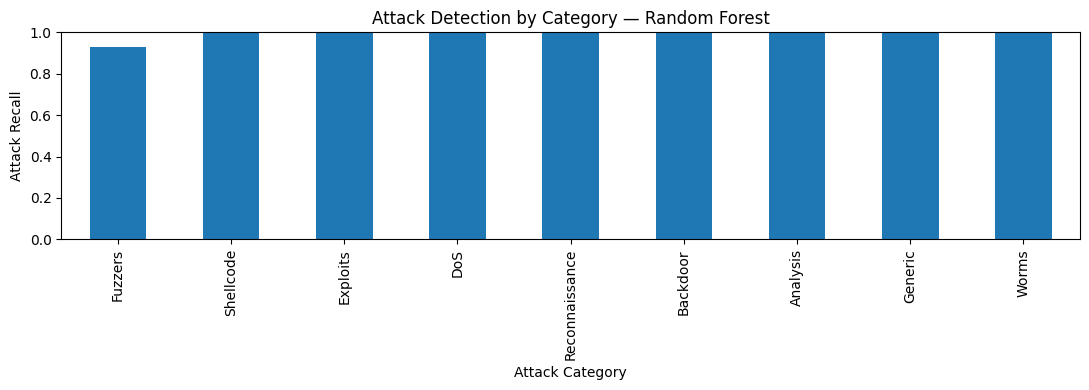

Attack category analysis completed.


In [39]:

# 07 — Attack Category Detection
# Best model was selected using Validation in Notebook 02.

assert "best_name" in globals(), (
    "Run Section 02 — Load Validation-Selected Model first."
)

assert best_name in results["Model"].values, (
    "Validation-selected model not found in test results."
)

pred_col = (
    best_name.lower().replace(" ", "_") + "_prediction"
)

assert pred_col in preds.columns, (
    f"Missing prediction column: {pred_col}"
)

# Analyze attack records only
attacks = preds[preds["actual"] == 1].copy()

attack_stats = attacks.groupby("attack_cat").agg(
    Attack_Records=("actual", "size"),
    Detected=(pred_col, "sum")
)

attack_stats["Missed"] = (
    attack_stats["Attack_Records"] - attack_stats["Detected"]
)

attack_stats["Attack_Recall"] = (
    attack_stats["Detected"] / attack_stats["Attack_Records"]
)

attack_stats = attack_stats.sort_values("Attack_Recall")

print("Validation-selected model:", best_name)
print("Attack detection performance by category:")

display(attack_stats)

# Save results
attack_stats.to_csv(
    OUT / "attack_category_detection.csv"
)

# Visualization
attack_stats["Attack_Recall"].plot.bar(
    figsize=(11, 4),
    ylim=(0, 1),
    title=f"Attack Detection by Category — {best_name}"
)

plt.ylabel("Attack Recall")
plt.xlabel("Attack Category")
plt.tight_layout()

plt.savefig(
    FIG / "attack_category_detection.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Attack category analysis completed.")


## 08 — Inspect Hardest Attack Categories

In [40]:
print('Most difficult categories (lowest detected proportion):')
display(attack_stats.head(4))
print('Easiest categories (highest detected proportion):')
display(attack_stats.tail(4))
print('Note: this is binary attack detection broken down by known categories, NOT multiclass prediction.')

Most difficult categories (lowest detected proportion):


,Attack_Records,Detected,Missed,Attack_Recall
attack_cat,,,,
Fuzzers,6062,5619,443,0.926922
Shellcode,378,376,2,0.994709
Exploits,11132,11097,35,0.996856
DoS,4089,4087,2,0.999511


Easiest categories (highest detected proportion):


,Attack_Records,Detected,Missed,Attack_Recall
attack_cat,,,,
Backdoor,583,583,0,1.0
Analysis,677,677,0,1.0
Generic,18871,18871,0,1.0
Worms,44,44,0,1.0


Note: this is binary attack detection broken down by known categories, NOT multiclass prediction.


## 09 — Explainability Results

,Feature,Mean F1 decrease,Std
0,service,0.011946,0.000902
1,ct_dst_src_ltm,0.010259,0.002165
2,synack,0.009800,0.000336
3,dmean,0.009736,0.001492
4,sbytes,0.008580,0.000909
5,ct_srv_dst,0.007147,0.001529
6,smean,0.005886,0.001190
7,sttl,0.005150,0.000943
8,tcprtt,0.005121,0.000614
9,ct_srv_src,0.004661,0.001305


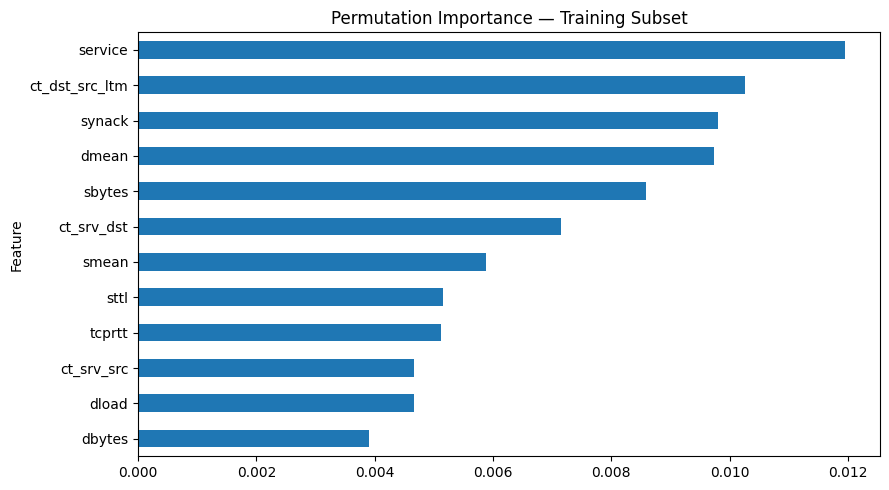

In [41]:
imp_path=OUT/'best_model_permutation_importance.csv'
if imp_path.is_file():
    imp=pd.read_csv(imp_path)
    display(imp.head(15))
    imp.head(12).sort_values('Mean F1 decrease').plot.barh(x='Feature',y='Mean F1 decrease',legend=False,figsize=(9,5),title='Permutation Importance — Training Subset')
    plt.tight_layout();plt.savefig(FIG/'final_feature_importance.png',dpi=150);plt.show()
else:
    print('Run Notebook 02 — Global Explainability to create the feature importance output.')

Display SHAP Results

SHAP — Global Feature Importance


,Feature,Mean absolute SHAP
0,num__sttl,0.070820
1,num__dttl,0.058290
2,num__ct_state_ttl,0.043889
3,num__swin,0.035596
4,cat__state_INT,0.028473
5,cat__proto_tcp,0.023465
6,num__ct_srv_dst,0.021307
7,num__sloss,0.018918
8,num__ackdat,0.016334
9,num__dbytes,0.015027


Displaying: shap_bar.png


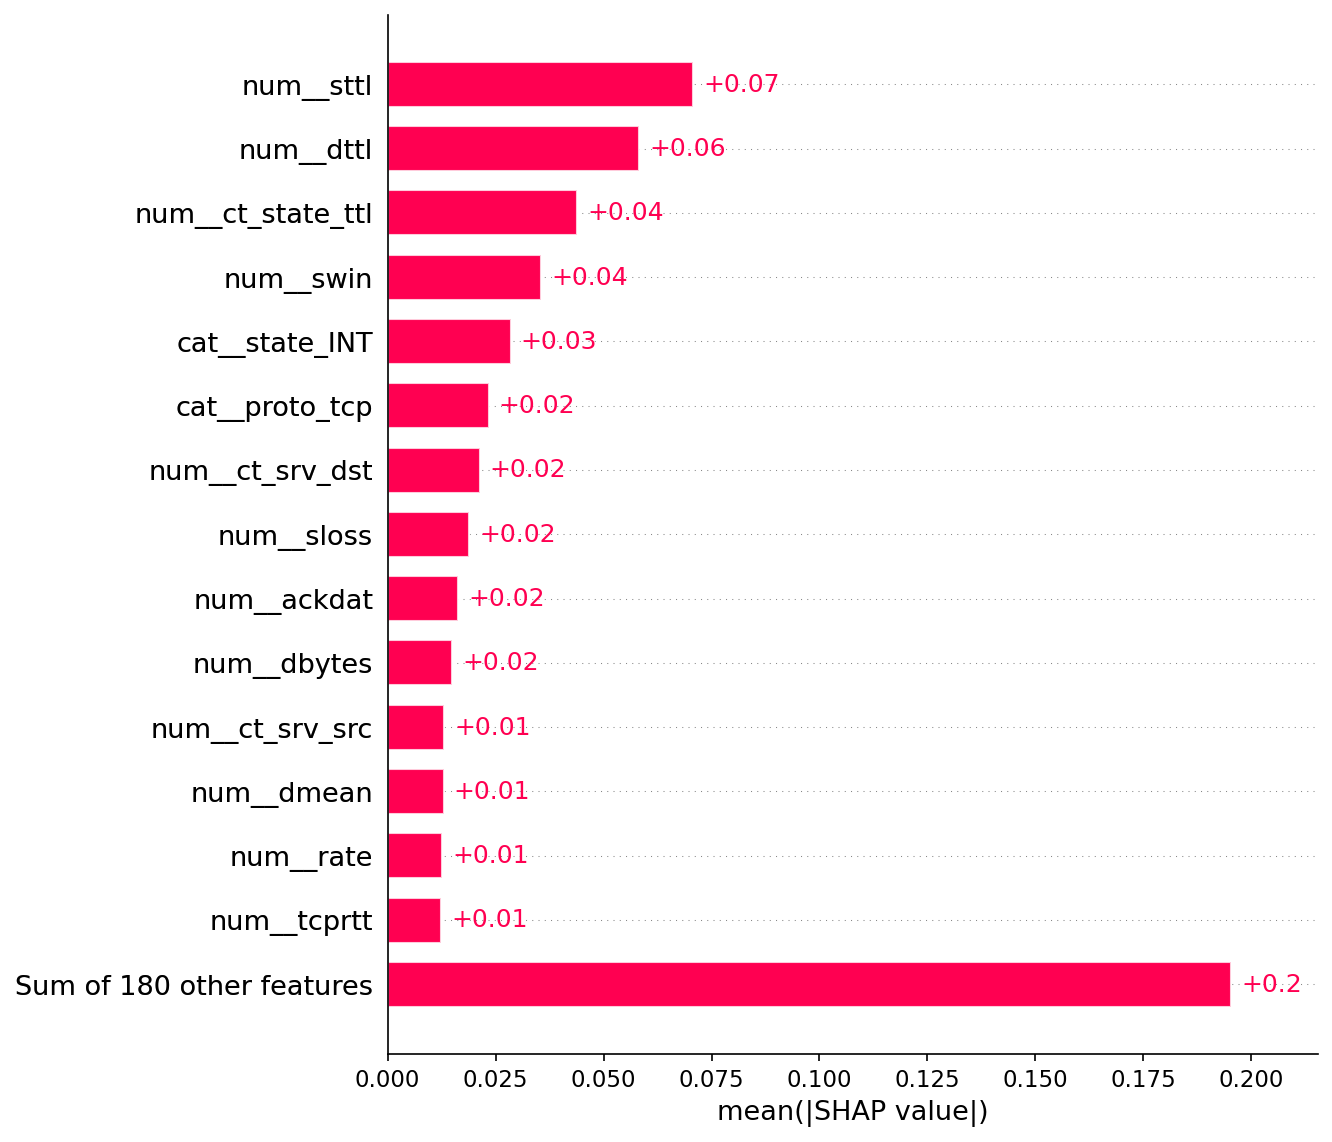

Displaying: shap_beeswarm.png


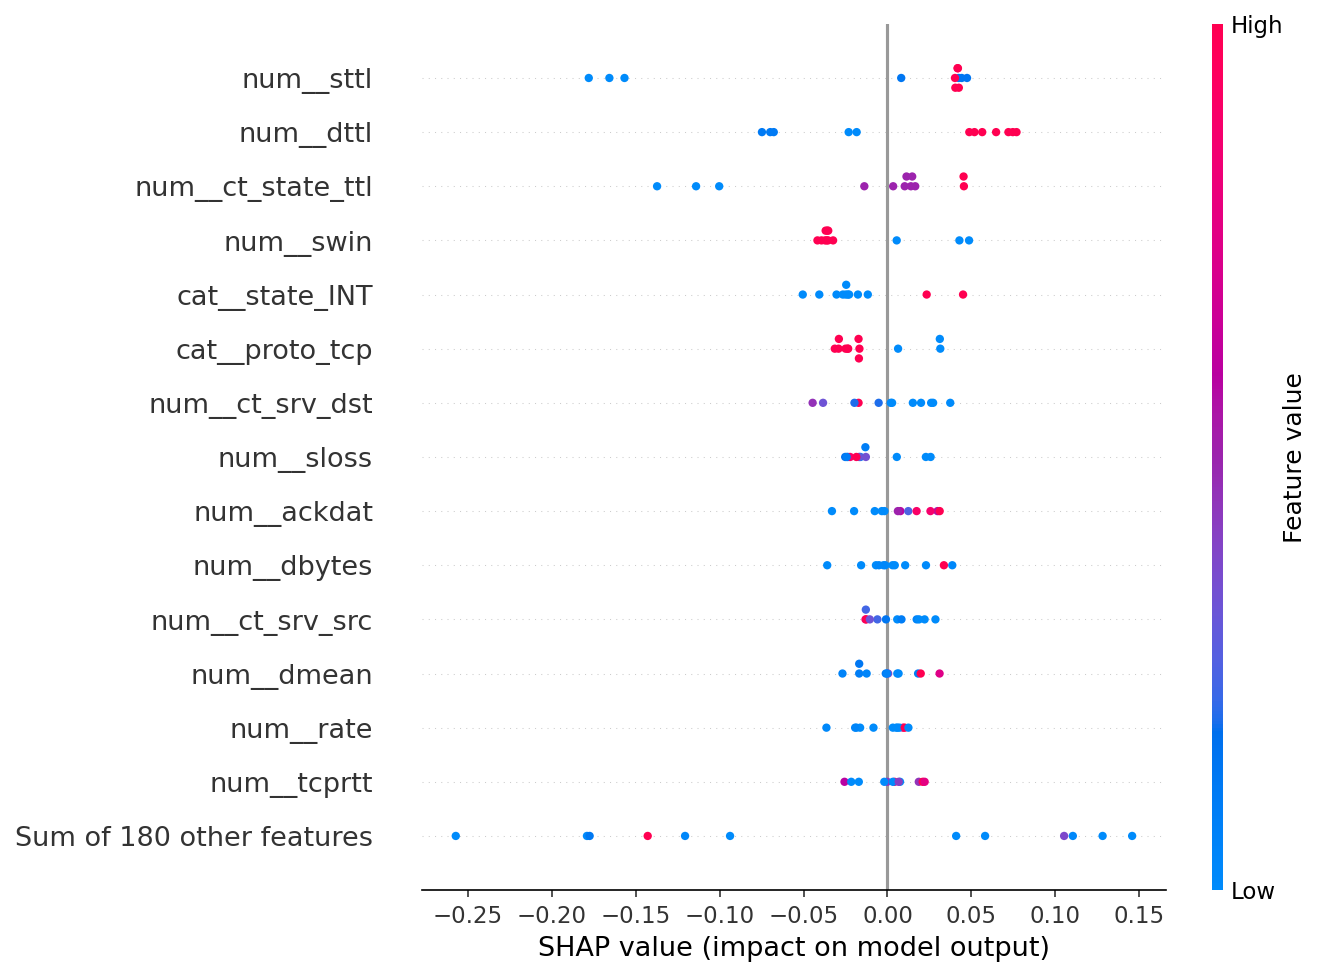

Displaying: shap_waterfall.png


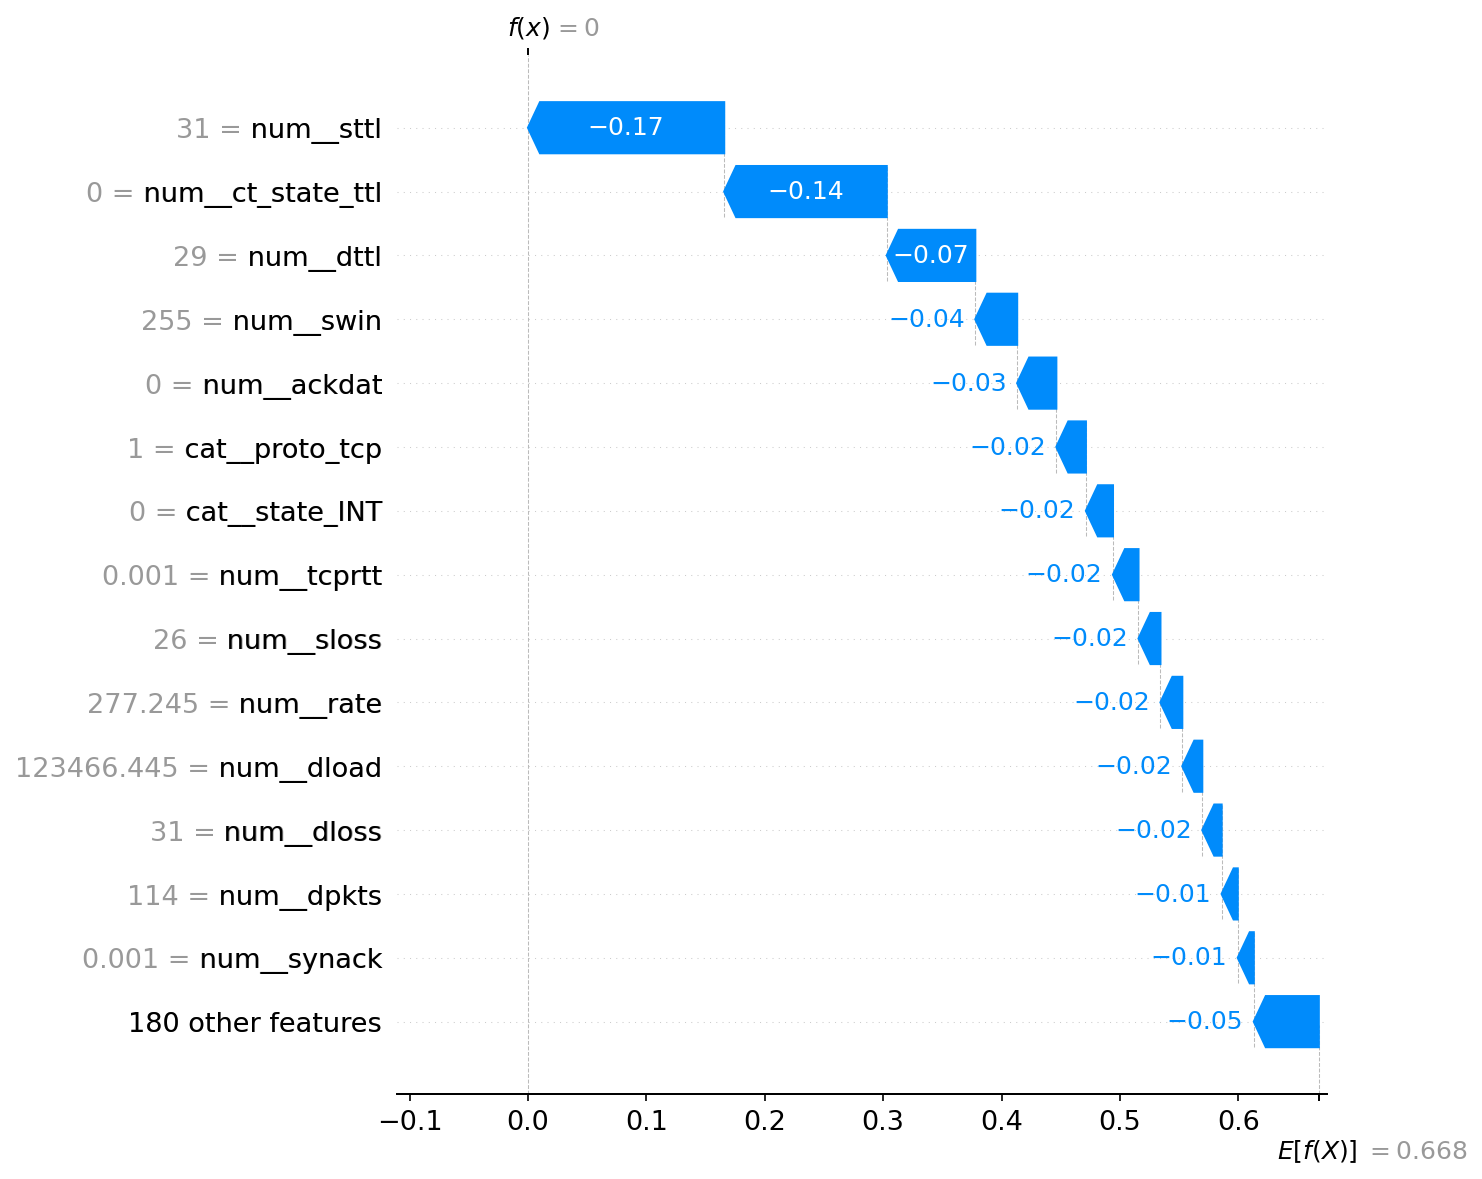

SHAP results displayed successfully.


In [42]:

from IPython.display import Image, display

shap_path = OUT / "shap_global_importance.csv"

assert shap_path.exists(), (
    "Run SHAP cell in Notebook 02 first."
)

shap_results = pd.read_csv(shap_path)

print("SHAP — Global Feature Importance")
display(shap_results.head(15))

plots = [
    "shap_bar.png",
    "shap_beeswarm.png",
    "shap_waterfall.png"
]

for name in plots:
    path = FIG / name

    assert path.exists(), f"Missing plot: {name}"

    print("Displaying:", name)
    display(Image(filename=str(path)))

print("SHAP results displayed successfully.")


## 10 — Cybersecurity Impact Summary

In [43]:

# 10 — Cybersecurity Impact Summary
# Final test results for the validation-selected model.

assert "best_name" in globals(), (
    "Run the Validation Model Selection loading cell first."
)

assert best_name in results["Model"].values
assert "attack_stats" in globals()

best = results.set_index("Model").loc[best_name]

summary = {
    "Selected model (validation F1)": best_name,
    "Selection method": "Validation F1-score",
    "Test Accuracy": float(best["Accuracy"]),
    "Test Precision": float(best["Precision"]),
    "Test Attack Recall": float(best["Recall"]),
    "Test F1": float(best["F1-score"]),
    "False Positives": int(best["FP"]),
    "False Negatives": int(best["FN"]),
    "Hardest Attack Category": str(attack_stats.index[0]),
    "Limitation": (
        "Fixed laboratory dataset, class imbalance, "
        "possible duplicate signatures across splits, "
        "and limited evidence of generalization "
        "to unseen real-world network traffic."
    )
}

print("FINAL CYBERSECURITY IMPACT SUMMARY")
print("=" * 45)

print(json.dumps(summary, indent=2))

# Save final summary
(OUT / "cybersecurity_summary.json").write_text(
    json.dumps(summary, indent=2),
    encoding="utf-8"
)

print("\nCYBERSECURITY INTERPRETATION")
print("-" * 45)

print(
    "The model was selected using validation data, "
    "rather than final test performance."
)

print(
    f"The selected model is {best_name}, "
    f"with Test F1 = {best['F1-score']:.4f} "
    f"and Attack Recall = {best['Recall']:.4f}."
)

print(
    f"False Negatives: {int(best['FN'])}. "
    "These are malicious network flows incorrectly "
    "classified as normal. Such errors may allow "
    "attacks to go undetected."
)

print(
    f"False Positives: {int(best['FP'])}. "
    "These are normal flows incorrectly classified "
    "as attacks. They may increase analyst workload "
    "and disrupt legitimate network activity."
)

print(
    f"The most difficult attack category was "
    f"{attack_stats.index[0]}, based on "
    "the lowest attack detection recall."
)

print(
    "Limitations include dataset imbalance, "
    "duplicate feature signatures, and uncertainty "
    "about generalization to real-world traffic."
)

print("\nSummary saved successfully.")


FINAL CYBERSECURITY IMPACT SUMMARY
{
  "Selected model (validation F1)": "Random Forest",
  "Selection method": "Validation F1-score",
  "Test Accuracy": 0.8651921488607103,
  "Test Precision": 0.8086000180293879,
  "Test Attack Recall": 0.9893452748610252,
  "Test F1": 0.889887595860988,
  "False Positives": 10616,
  "False Negatives": 483,
  "Hardest Attack Category": "Fuzzers",
  "Limitation": "Fixed laboratory dataset, class imbalance, possible duplicate signatures across splits, and limited evidence of generalization to unseen real-world network traffic."
}

CYBERSECURITY INTERPRETATION
---------------------------------------------
The model was selected using validation data, rather than final test performance.
The selected model is Random Forest, with Test F1 = 0.8899 and Attack Recall = 0.9893.
False Negatives: 483. These are malicious network flows incorrectly classified as normal. Such errors may allow attacks to go undetected.
False Positives: 10616. These are normal flows i

## 11 — Final Submission Files

In [44]:
required=['model_comparison.csv','test_predictions.csv','security_errors.csv','attack_category_detection.csv','cybersecurity_summary.json','best_model_permutation_importance.csv']
for name in required:
    p=OUT/name
    print(('OK ' if p.exists() else 'MISSING ')+str(p))
print('Raw train/test CSV files live in:',RAW)
print('Written PDF report is required separately by the project instructions.')

OK /content/drive/MyDrive/CAI470_Project/outputs/model_comparison.csv
OK /content/drive/MyDrive/CAI470_Project/outputs/test_predictions.csv
OK /content/drive/MyDrive/CAI470_Project/outputs/security_errors.csv
OK /content/drive/MyDrive/CAI470_Project/outputs/attack_category_detection.csv
OK /content/drive/MyDrive/CAI470_Project/outputs/cybersecurity_summary.json
OK /content/drive/MyDrive/CAI470_Project/outputs/best_model_permutation_importance.csv
Raw train/test CSV files live in: /content/drive/MyDrive/CAI470_Project/raw
Written PDF report is required separately by the project instructions.
